# From Pantry to Passport 🍅✈️
## Predicting Cuisine from Ingredient Lists — and Testing Whether Models Understand Food or Just Memorise Words

**Course:** Natural Language Processing   
Imam Abdulrahman Bin Faisal University, CCSIT  
**Project option:** Option 4 — Student-Proposed NLP Project  
**Group:** 10 · **Section:** 7FA2  
**Team:** _[Team Leader — Maisoon Alanbdullah, 2240005251]_ · _[Member 2 — Joli Salama, 2240004580]_ · _[Member 3 — Wajd Alkhaldi, 2240005544]_ ·  _[Member 4 — Manar Alghamdi, 2240005128]_

---

### What this notebook does
You type a list of ingredients, and the system predicts which of **20 cuisines** the recipe comes from.

| Input | Output |
|---|---|
| `tomato, garlic, olive oil, basil, parmesan cheese` | **italian** |
| `soy sauce, ginger, sesame oil, tofu, green onions` | **chinese** |

### Our experimental question
> **When ingredient names are replaced with verified synonyms or regional names (for example *eggplant → aubergine*), which method keeps its Macro F1 better: TF‑IDF + Logistic Regression, or pretrained MiniLM sentence embeddings + Logistic Regression?**

### Why this is an interesting NLP problem
The same ingredient often has more than one name. An American cook writes *zucchini*; a British cook writes *courgette*. A model that only counts words sees two unrelated words. A pretrained language model may already know they mean the same thing. We test this directly and fairly.

### Notebook map
| Section | Content |
|---|---|
| 0 | Setup |
| 1 | Data |
| 2 | Cleaning |
| 3 | Fair train / dev / test split |
| 4 | Verified ingredient-name substitutions (the robustness test set) |
| 5 | Method 1 — TF‑IDF + Logistic Regression |
| 6 | Method 2 — MiniLM embeddings + Logistic Regression |
| 7 | Results |
| 8 | Error analysis |
| 9 | Our own labelled examples |
| 10 | **Try it** |
| 11 | Saved results summary |
| 12 | Sources |

### How to run
Built for **Google Colab** (a GPU runtime makes Section 6 faster, but CPU also works).
Use **Runtime → Run all**. Every result in the report comes from this notebook, and all results are saved to the `results/` folder.

# 0. Setup
 We fix a **random seed** so the split and the models are the same every time we run the notebook.

In [14]:
# Install only what is missing (Colab already has scikit-learn, pandas, matplotlib)
import importlib, subprocess, sys
for pkg, pip_name in [("sentence_transformers", "sentence-transformers"), ("kagglehub", "kagglehub")]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_name], check=False)

In [15]:
import json, re, time, unicodedata, hashlib, platform, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import joblib
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Relative folders (they are created next to the notebook)
PROJECT_DIR = Path.cwd()
DATA_DIR    = PROJECT_DIR / "data"
MODELS_DIR  = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results"
FIG_DIR     = PROJECT_DIR / "figures"
CACHE_DIR   = PROJECT_DIR / "cache"
for d in [DATA_DIR, MODELS_DIR, RESULTS_DIR, FIG_DIR, CACHE_DIR]:
    d.mkdir(exist_ok=True)

# Consistent figure style for the report and slides
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
COLOR_TFIDF, COLOR_EMB = "#2a6f97", "#e07a5f"

import sentence_transformers
print("Python              ", platform.python_version())
print("numpy               ", np.__version__)
print("pandas              ", pd.__version__)
print("scikit-learn        ", sklearn.__version__)
print("sentence-transformers", sentence_transformers.__version__)
try:
    import torch
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
    print("torch               ", torch.__version__, "| device:", DEVICE)
except ImportError:
    DEVICE = "cpu"

Python               3.13.16
numpy                2.1.3
pandas               2.2.3
scikit-learn         1.6.1
sentence-transformers 5.7.0
torch                2.11.0+cu130 | device: cuda


# 1. Data
**Dataset:** *What's Cooking?* (Yummly recipes, released by Kaggle). Each recipe has an `id`, a `cuisine` label and a list of `ingredients`.
We use only `train.json`, because the original Kaggle test file has no labels.

**Getting the file.** The cell below looks for the file in this order, so it works on any computer:
1. `data/train.json` next to this notebook ;
2. automatic download from Kaggle's public copy (*Recipe Ingredients Dataset*) with `kagglehub`;
3. your Google Drive at `MyDrive/NLP_Project/data/train.json` (Colab only);
4. a file-upload box (Colab only).

In [16]:
DATA_FILE = DATA_DIR / "train.json"
DRIVE_FILE = Path("/content/drive/MyDrive/NLP_Project/data/train.json")

def get_data_file():
    """Return a path to train.json, trying local file -> Kaggle -> Google Drive -> upload."""
    if DATA_FILE.exists():
        print("Found local file:", DATA_FILE)
        return DATA_FILE
    # 2) Kaggle public dataset
    try:
        import kagglehub, shutil
        folder = Path(kagglehub.dataset_download("kaggle/recipe-ingredients-dataset"))
        found = list(folder.rglob("train.json"))
        if found:
            shutil.copy(found[0], DATA_FILE)
            print("Downloaded from Kaggle ->", DATA_FILE)
            return DATA_FILE
    except Exception as e:
        print("Kaggle download did not work:", type(e).__name__, str(e)[:120])
    # 3) Google Drive (Colab)
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        if DRIVE_FILE.exists():
            import shutil
            shutil.copy(DRIVE_FILE, DATA_FILE)
            print("Copied from Google Drive ->", DATA_FILE)
            return DATA_FILE
    except Exception as e:
        print("Google Drive not available:", type(e).__name__)
    # 4) Manual upload (Colab)
    try:
        from google.colab import files
        print("Please upload train.json")
        uploaded = files.upload()
        name = next(iter(uploaded))
        DATA_FILE.write_bytes(uploaded[name])
        return DATA_FILE
    except Exception:
        pass
    raise FileNotFoundError("train.json not found. Put it in the data/ folder next to this notebook.")

data_path = get_data_file()
raw = pd.read_json(data_path)
print(f"\nLoaded {len(raw):,} recipes with columns {list(raw.columns)}")
raw.head()

Found local file: /content/data/train.json

Loaded 39,774 recipes with columns ['id', 'cuisine', 'ingredients']


,id,cuisine,ingredients
0,10259,greek,"[romaine lettuce, black olives, grape tomatoes, garlic, pepper, purple onion, seasoning, garbanzo beans, feta cheese..."
1,25693,southern_us,"[plain flour, ground pepper, salt, tomatoes, ground black pepper, thyme, eggs, green tomatoes, yellow corn meal, mil..."
2,20130,filipino,"[eggs, pepper, salt, mayonaise, cooking oil, green chilies, grilled chicken breasts, garlic powder, yellow onion, so..."
3,22213,indian,"[water, vegetable oil, wheat, salt]"
4,13162,indian,"[black pepper, shallots, cornflour, cayenne pepper, onions, garlic paste, milk, butter, salt, lemon juice, water, ch..."


cuisine,italian,mexican,southern_us,indian,chinese,french,cajun_creole,thai,japanese,greek,spanish,korean,vietnamese,moroccan,british,filipino,irish,jamaican,russian,brazilian
recipes,7838.0,6438.0,4320.0,3003.0,2673.0,2646.0,1546.0,1539.0,1423.0,1175.0,989.0,830.0,825.0,821.0,804.0,755.0,667.0,526.0,489.0,467.0
share_%,19.7,16.2,10.9,7.6,6.7,6.7,3.9,3.9,3.6,3.0,2.5,2.1,2.1,2.1,2.0,1.9,1.7,1.3,1.2,1.2


Cuisines: 20 | ingredients per recipe: median 10, min 1, max 65
Largest class / smallest class = 16.8x


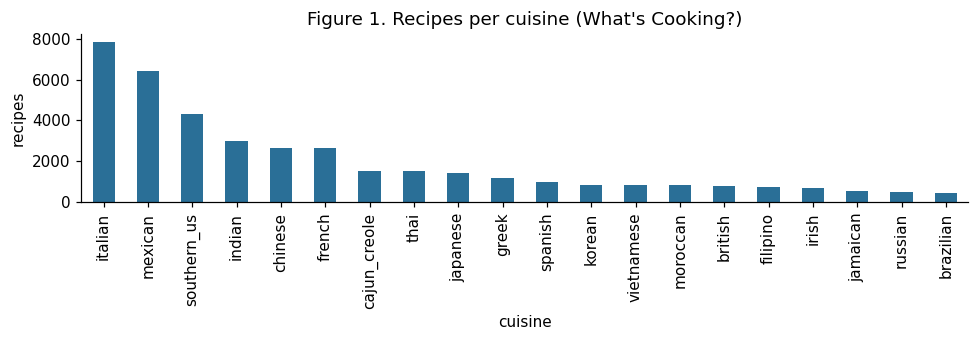

In [17]:
# Class counts: the dataset is very unbalanced, which is why we report Macro F1
counts = raw["cuisine"].value_counts()
class_table = pd.DataFrame({"recipes": counts, "share_%": (100 * counts / counts.sum()).round(1)})
class_table.to_csv(RESULTS_DIR / "class_counts.csv")
display(class_table.T)

n_ings = raw["ingredients"].apply(len)
print(f"Cuisines: {raw['cuisine'].nunique()} | ingredients per recipe: "
      f"median {n_ings.median():.0f}, min {n_ings.min()}, max {n_ings.max()}")
print(f"Largest class / smallest class = {counts.max() / counts.min():.1f}x")

fig, ax = plt.subplots(figsize=(9, 3.2))
counts.plot(kind="bar", ax=ax, color=COLOR_TFIDF)
ax.set_ylabel("recipes"); ax.set_title("Figure 1. Recipes per cuisine (What's Cooking?)")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig1_class_counts.png"); plt.show()

# 2. Cleaning
We keep cleaning **light and transparent**:
- change to lowercase and remove accents and symbols such as ™ or ®;
- remove numbers and punctuation (for example `(10 oz.)`);
- remove repeated ingredients inside the same recipe.

**What we deliberately do *not* do** : no lemmatising, no spelling correction and no synonym normalisation. If cleaning changed *aubergine* back into *eggplant*, the robustness test would secretly disappear. Section 5.3 checks this with code.

**How each model sees a recipe**
- *TF‑IDF* gets the individual words **plus** one token for each multi-word ingredient (e.g. `olive oil olive_oil`), so it can learn from both “olive” and the full phrase “olive oil”.
- *MiniLM* gets a natural sentence: `Ingredients: tomato, garlic, olive oil.`

In [18]:
def clean_ingredient(text):
    """Lowercase, strip accents/symbols/digits/punctuation, collapse spaces."""
    text = unicodedata.normalize("NFKD", str(text)).encode("ascii", "ignore").decode()
    text = text.lower().replace("&", " and ")
    text = re.sub(r"[^a-z\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

def clean_recipe(ingredients):
    """Clean every ingredient and drop empty or repeated ones (order kept)."""
    out = []
    for ing in ingredients:
        c = clean_ingredient(ing)
        if c and c not in out:
            out.append(c)
    return out

def to_tfidf_text(phrases):
    """Words + one joined token per multi-word ingredient: 'olive oil' -> 'olive oil olive_oil'."""
    words = " ".join(phrases)
    joined = " ".join(p.replace(" ", "_") for p in phrases if " " in p)
    return (words + " " + joined).strip()

def to_sentence(phrases):
    """Natural sentence for the pretrained sentence encoder."""
    return "Ingredients: " + ", ".join(phrases) + "."

df = raw.copy()
df["clean"] = df["ingredients"].apply(clean_recipe)
before = len(df)
df = df[df["clean"].str.len() > 0].reset_index(drop=True)
print(f"Removed {before - len(df)} recipes with no usable ingredients")

# Exact duplicates = same set of cleaned ingredients (order does not matter)
df["group_key"] = df["clean"].apply(lambda p: "|".join(sorted(p)))
df["group_id"] = df["group_key"].factorize()[0]
dup_sizes = df["group_key"].value_counts()
n_dup_groups = int((dup_sizes > 1).sum())
n_in_dups = int(dup_sizes[dup_sizes > 1].sum())
conflicting = df.groupby("group_key")["cuisine"].nunique()
print(f"Duplicate ingredient sets: {n_dup_groups} groups covering {n_in_dups} recipes "
      f"({int((conflicting > 1).sum())} groups have different cuisine labels)")
print("These duplicates will always be kept inside the same split (Section 3).")

ex = df.iloc[0]
print("\nExample raw    :", ex["ingredients"][:6])
print("Example cleaned:", ex["clean"][:6])
print("TF-IDF text    :", to_tfidf_text(ex["clean"][:4]))
print("MiniLM sentence:", to_sentence(ex["clean"][:4]))

Removed 0 recipes with no usable ingredients
Duplicate ingredient sets: 503 groups covering 1037 recipes (14 groups have different cuisine labels)
These duplicates will always be kept inside the same split (Section 3).

Example raw    : ['romaine lettuce', 'black olives', 'grape tomatoes', 'garlic', 'pepper', 'purple onion']
Example cleaned: ['romaine lettuce', 'black olives', 'grape tomatoes', 'garlic', 'pepper', 'purple onion']
TF-IDF text    : romaine lettuce black olives grape tomatoes garlic romaine_lettuce black_olives grape_tomatoes
MiniLM sentence: Ingredients: romaine lettuce, black olives, grape tomatoes, garlic.


# 3. Fair train / dev / test split
- **70% train** — the models learn from these recipes.
- **15% dev** — we choose model settings here.
- **15% test** — used only once, for the final comparison.

We use `StratifiedGroupKFold`. *Stratified* keeps the same share of each cuisine in every split. *Group* keeps duplicate recipes together, so the same recipe can never appear in both training and testing. The `assert` lines prove there is no overlap.

In [19]:
sgkf = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=RANDOM_STATE)
fold = np.empty(len(df), dtype=int)
for k, (_, idx) in enumerate(sgkf.split(df, df["cuisine"], groups=df["group_id"])):
    fold[idx] = k
df["split"] = np.where(fold < 3, "test", np.where(fold < 6, "dev", "train"))

train_df = df[df["split"] == "train"].reset_index(drop=True)
dev_df   = df[df["split"] == "dev"].reset_index(drop=True)
test_df  = df[df["split"] == "test"].reset_index(drop=True)

# Proof of a fair split: no shared recipe ids and no shared duplicate groups
for a, b in [(train_df, dev_df), (train_df, test_df), (dev_df, test_df)]:
    assert not set(a["id"]) & set(b["id"]), "recipe id overlap!"
    assert not set(a["group_id"]) & set(b["group_id"]), "duplicate group overlap!"
print("✔ No recipe or duplicate group is shared between train, dev and test.")

split_table = pd.DataFrame({
    "recipes": [len(train_df), len(dev_df), len(test_df)],
    "share_%": [round(100 * len(x) / len(df), 1) for x in (train_df, dev_df, test_df)],
    "smallest class": [x["cuisine"].value_counts().min() for x in (train_df, dev_df, test_df)],
}, index=["train", "dev", "test"])
split_table.to_csv(RESULTS_DIR / "split_sizes.csv")
display(split_table)

# Labels as integers (same order everywhere)
CUISINES = sorted(df["cuisine"].unique())
LABEL2ID = {c: i for i, c in enumerate(CUISINES)}
y_train = train_df["cuisine"].map(LABEL2ID).values
y_dev   = dev_df["cuisine"].map(LABEL2ID).values
y_test  = test_df["cuisine"].map(LABEL2ID).values

✔ No recipe or duplicate group is shared between train, dev and test.


,recipes,share_%,smallest class
train,27838,70.0,317
dev,5964,15.0,61
test,5972,15.0,67


# 4. Verified ingredient-name substitutions
This is the heart of the project. We build a second copy of the test set where some ingredient names are changed to **another name for exactly the same ingredient** (mostly American → British / international).

### How we verified each pair (instructor note 1)
Each pair was checked against the question: *“Would a cook buy exactly the same product?”*
- **✅ Applied** — the same ingredient, the same form and the same part of the plant.
- **❌ Not applied** — similar, but not identical (a different plant part, a different fat content, a different product in different countries…). We still list these pairs, with the reason, to show the checking.

**The key example.** In American recipes, *cilantro* means the **fresh leaves**, while *coriander* often means the **seeds** (a dried spice with a different taste). So we change `cilantro → coriander leaf`, and we **never** touch `ground coriander` or `coriander seeds`.

### How the changes are applied
- only to the **test** recipes (never to training data);
- whole words only (`\b` word boundaries), **longest phrase first**, so `cilantro leaves` is handled before `cilantro`;
- every match in every recipe, with no randomness, so the result is always the same;
- all changes are logged, so we can count exactly which recipes were affected.

In [20]:
# ✅ Applied pairs: (original name in the dataset, replacement, region of replacement, reason)
SUBSTITUTIONS = [
    ("cilantro leaves",   "coriander leaves",    "UK/Intl", "US cilantro = the fresh leaves of the coriander plant"),
    ("cilantro sprigs",   "coriander sprigs",    "UK/Intl", "Same fresh herb (leaves and stems)"),
    ("cilantro",          "coriander leaf",      "UK/Intl", "Fresh leaves only; 'leaf' added so it cannot mean the seeds"),
    ("eggplants",         "aubergines",          "UK",      "Same vegetable (Solanum melongena)"),
    ("eggplant",          "aubergine",           "UK",      "Same vegetable (Solanum melongena)"),
    ("zucchini",          "courgette",           "UK",      "Same vegetable (Cucurbita pepo, immature fruit)"),
    ("arugula",           "rocket",              "UK",      "Same leaf (Eruca vesicaria)"),
    ("garbanzo beans",    "chickpeas",           "UK/Intl", "Same legume (Cicer arietinum)"),
    ("baking soda",       "bicarbonate of soda", "UK",      "Same chemical (sodium bicarbonate)"),
    ("powdered sugar",    "icing sugar",         "UK",      "Same product (finely ground sugar)"),
    ("confectioners sugar","icing sugar",        "UK",      "Same product (finely ground sugar)"),
    ("all purpose flour", "plain flour",         "UK",      "Same product (general wheat flour, no raising agent)"),
    ("green onions",      "spring onions",       "UK",      "Same vegetable (Allium fistulosum / young onion)"),
    ("green onion",       "spring onion",        "UK",      "Same vegetable"),
    ("scallions",         "spring onions",       "UK",      "Same vegetable"),
    ("scallion",          "spring onion",        "UK",      "Same vegetable"),
    ("ground beef",       "beef mince",          "UK",      "Same product (minced beef)"),
    ("ground pork",       "pork mince",          "UK",      "Same product (minced pork)"),
    ("ground turkey",     "turkey mince",        "UK",      "Same product (minced turkey)"),
    ("ground lamb",       "lamb mince",          "UK",      "Same product (minced lamb)"),
    ("bell peppers",      "capsicums",           "AU/India","Same vegetable (sweet Capsicum annuum)"),
    ("bell pepper",       "capsicum",            "AU/India","Same vegetable (sweet Capsicum annuum)"),
    ("fava beans",        "broad beans",         "UK",      "Same bean (Vicia faba)"),
    ("lima beans",        "butter beans",        "UK",      "Same bean (Phaseolus lunatus)"),
    ("beets",             "beetroot",            "UK",      "Same root vegetable (Beta vulgaris)"),
    ("rutabaga",          "swede",               "UK",      "Same root vegetable (Brassica napus)"),
    ("romaine lettuce",   "cos lettuce",         "UK/AU",   "Same lettuce variety"),
    ("green beans",       "french beans",        "UK",      "Same bean (immature Phaseolus vulgaris pods)"),
    ("skim milk",         "skimmed milk",        "UK",      "Same product (fat-free milk)"),
    ("cantaloupe",        "rockmelon",           "AU",      "Same melon"),
]

# ❌ Checked but NOT applied (similar, but not the same ingredient)
EXCLUDED = [
    ("ground coriander / coriander seeds", "cilantro",       "Seeds are a different plant part with a different taste"),
    ("heavy cream",       "double cream",     "Different fat content (about 36% vs 48%)"),
    ("shrimp",            "prawns",           "Strictly different animals; names overlap by region"),
    ("cornstarch",        "cornflour",        "'Corn flour' means a different product in the US"),
    ("tomato paste",      "tomato puree",     "'Tomato puree' means different products in the US and UK"),
    ("chili powder",      "chilli powder",    "US chili powder is a spice blend; UK chilli powder is pure chilli"),
    ("granulated sugar",  "caster sugar",     "Caster sugar is ground finer"),
    ("golden raisins",    "sultanas",         "Different grape variety / drying process"),
    ("canola oil",        "rapeseed oil",     "Canola is one specific type of rapeseed"),
    ("snow peas",         "mangetout",        "UK 'mangetout' also includes sugar snap peas"),
    ("molasses",          "black treacle",    "Different products with different taste"),
]

subs_table = pd.DataFrame(SUBSTITUTIONS, columns=["original", "replacement", "region", "why it is the same ingredient"])
subs_table.insert(0, "status", "✅ applied")
excl_table = pd.DataFrame(EXCLUDED, columns=["original", "replacement", "why it is NOT applied"])
excl_table.insert(0, "status", "❌ not applied")
subs_table.to_csv(RESULTS_DIR / "substitutions_applied.csv", index=False)
excl_table.to_csv(RESULTS_DIR / "substitutions_excluded.csv", index=False)
print(f"Table 1. {len(SUBSTITUTIONS)} verified substitutions applied")
display(subs_table)
print(f"Table 2. {len(EXCLUDED)} pairs checked and rejected")
display(excl_table)

Table 1. 30 verified substitutions applied


,status,original,replacement,region,why it is the same ingredient
0,✅ applied,cilantro leaves,coriander leaves,UK/Intl,US cilantro = the fresh leaves of the coriander plant
1,✅ applied,cilantro sprigs,coriander sprigs,UK/Intl,Same fresh herb (leaves and stems)
2,✅ applied,cilantro,coriander leaf,UK/Intl,Fresh leaves only; 'leaf' added so it cannot mean the seeds
3,✅ applied,eggplants,aubergines,UK,Same vegetable (Solanum melongena)
4,✅ applied,eggplant,aubergine,UK,Same vegetable (Solanum melongena)
5,✅ applied,zucchini,courgette,UK,"Same vegetable (Cucurbita pepo, immature fruit)"
6,✅ applied,arugula,rocket,UK,Same leaf (Eruca vesicaria)
7,✅ applied,garbanzo beans,chickpeas,UK/Intl,Same legume (Cicer arietinum)
8,✅ applied,baking soda,bicarbonate of soda,UK,Same chemical (sodium bicarbonate)
9,✅ applied,powdered sugar,icing sugar,UK,Same product (finely ground sugar)


Table 2. 11 pairs checked and rejected


,status,original,replacement,why it is NOT applied
0,❌ not applied,ground coriander / coriander seeds,cilantro,Seeds are a different plant part with a different taste
1,❌ not applied,heavy cream,double cream,Different fat content (about 36% vs 48%)
2,❌ not applied,shrimp,prawns,Strictly different animals; names overlap by region
3,❌ not applied,cornstarch,cornflour,'Corn flour' means a different product in the US
4,❌ not applied,tomato paste,tomato puree,'Tomato puree' means different products in the US and UK
5,❌ not applied,chili powder,chilli powder,US chili powder is a spice blend; UK chilli powder is pure chilli
6,❌ not applied,granulated sugar,caster sugar,Caster sugar is ground finer
7,❌ not applied,golden raisins,sultanas,Different grape variety / drying process
8,❌ not applied,canola oil,rapeseed oil,Canola is one specific type of rapeseed
9,❌ not applied,snow peas,mangetout,UK 'mangetout' also includes sugar snap peas


In [21]:
SUB_MAP = {orig: new for orig, new, *_ in SUBSTITUTIONS}
# One regex, longest phrase first, whole words only
SUB_PATTERN = re.compile(
    r"\b(" + "|".join(re.escape(k) for k in sorted(SUB_MAP, key=len, reverse=True)) + r")\b")

def reword_recipe(phrases):
    """Apply the verified substitutions to a cleaned recipe. Returns (new_phrases, list_of_applied_keys)."""
    applied = []
    def repl(m):
        applied.append(m.group(1))
        return SUB_MAP[m.group(1)]
    new = [SUB_PATTERN.sub(repl, p) for p in phrases]
    return new, applied

# Unit tests for the rules described above
assert reword_recipe(["fresh cilantro"])[0] == ["fresh coriander leaf"]
assert reword_recipe(["cilantro leaves"])[0] == ["coriander leaves"]          # longest match first
assert reword_recipe(["ground coriander", "coriander seeds"])[0] == ["ground coriander", "coriander seeds"]  # seeds untouched
assert reword_recipe(["beet greens"])[0] == ["beet greens"]                   # whole words only
assert reword_recipe(["chopped green onions", "eggplant"])[1] == ["green onions", "eggplant"]
print("✔ Substitution rules pass all unit tests.")

# Build the reworded test set
reworded = test_df["clean"].apply(reword_recipe)
test_df["clean_reworded"] = reworded.str[0]
test_df["applied"] = reworded.str[1]
test_df["n_subs"] = test_df["applied"].str.len()
test_df["affected"] = test_df["n_subs"] > 0
affected = test_df["affected"].values

# Text versions for both models, original and reworded
X_tr_txt   = train_df["clean"].apply(to_tfidf_text)
X_dev_txt  = dev_df["clean"].apply(to_tfidf_text)
X_te_txt   = test_df["clean"].apply(to_tfidf_text)
X_terw_txt = test_df["clean_reworded"].apply(to_tfidf_text)
S_tr, S_dev = train_df["clean"].apply(to_sentence), dev_df["clean"].apply(to_sentence)
S_te, S_terw = test_df["clean"].apply(to_sentence), test_df["clean_reworded"].apply(to_sentence)

# Example before / after
for _, r in test_df[test_df["affected"]].head(3).iterrows():
    print(f"[{r['cuisine']}]\n  before: {', '.join(r['clean'])}\n  after : {', '.join(r['clean_reworded'])}\n")

✔ Substitution rules pass all unit tests.
[greek]
  before: romaine lettuce, black olives, grape tomatoes, garlic, pepper, purple onion, seasoning, garbanzo beans, feta cheese crumbles
  after : cos lettuce, black olives, grape tomatoes, garlic, pepper, purple onion, seasoning, chickpeas, feta cheese crumbles

[british]
  before: greek yogurt, lemon curd, confectioners sugar, raspberries
  after : greek yogurt, lemon curd, icing sugar, raspberries

[thai]
  before: pork loin, roasted peanuts, chopped cilantro fresh, hoisin sauce, creamy peanut butter, chopped fresh mint, thai basil, rice, medium shrimp, water, rice noodles, beansprouts
  after : pork loin, roasted peanuts, chopped coriander leaf fresh, hoisin sauce, creamy peanut butter, chopped fresh mint, thai basil, rice, medium shrimp, water, rice noodles, beansprouts



### 4.1 Coverage: how many test recipes are really changed?
The changed recipes are called the **affected subset**. Results on the full test set are “diluted”, because most recipes have no changed word, so we report both.

The last table also asks a very important question: **has each new name already appeared in the training data?** If *chickpeas* already appears in many training recipes, the TF‑IDF model knows it, so it is not truly “unfamiliar” for that model.

In [22]:
n_aff = int(affected.sum())
coverage = {
    "test recipes": len(test_df),
    "affected recipes": n_aff,
    "affected %": round(100 * n_aff / len(test_df), 1),
    "total substitutions": int(test_df["n_subs"].sum()),
    "mean substitutions per affected recipe": round(test_df.loc[affected, "n_subs"].mean(), 2),
}
display(pd.Series(coverage, name="Table 3. Coverage").to_frame())

per_cuisine = (test_df.groupby("cuisine")["affected"].agg(["sum", "count"])
               .rename(columns={"sum": "affected", "count": "test recipes"}))
per_cuisine["affected %"] = (100 * per_cuisine["affected"] / per_cuisine["test recipes"]).round(1)
per_cuisine = per_cuisine.sort_values("affected %", ascending=False)
per_cuisine.to_csv(RESULTS_DIR / "coverage_per_cuisine.csv")
print("Table 4. Affected recipes per cuisine")
display(per_cuisine.T)

# How often each original / replacement phrase already appears in TRAINING recipes
train_joined = train_df["clean"].apply(lambda p: " | ".join(p))
def n_train_recipes(phrase):
    return int(train_joined.str.contains(r"\b" + re.escape(phrase) + r"\b", regex=True).sum())

pair_hits = Counter(k for keys in test_df["applied"] for k in set(keys))
pair_rows = []
for orig, new, *_ in SUBSTITUTIONS:
    pair_rows.append({"original": orig, "replacement": new,
                      "test recipes changed": pair_hits.get(orig, 0),
                      "train recipes with original": n_train_recipes(orig),
                      "train recipes with replacement": n_train_recipes(new)})
pair_table = pd.DataFrame(pair_rows).sort_values("test recipes changed", ascending=False)
pair_table.to_csv(RESULTS_DIR / "coverage_per_pair.csv", index=False)
print("Table 5. Use of each substitution, and whether the new name was ever seen in training")
display(pair_table)

,Table 3. Coverage
test recipes,5972.0
affected recipes,2964.0
affected %,49.6
total substitutions,4162.0
mean substitutions per affected recipe,1.4


Table 4. Affected recipes per cuisine


cuisine,korean,thai,vietnamese,cajun_creole,chinese,mexican,moroccan,russian,jamaican,british,irish,southern_us,indian,japanese,filipino,spanish,greek,french,italian,brazilian
affected,100.0,165.0,87.0,170.0,271.0,612.0,82.0,40.0,35.0,60.0,45.0,272.0,203.0,86.0,44.0,63.0,64.0,143.0,396.0,26.0
test recipes,140.0,238.0,128.0,252.0,426.0,964.0,133.0,71.0,67.0,115.0,92.0,619.0,465.0,205.0,106.0,153.0,169.0,394.0,1146.0,89.0
affected %,71.4,69.3,68.0,67.5,63.6,63.5,61.7,56.3,52.2,52.2,48.9,43.9,43.7,42.0,41.5,41.2,37.9,36.3,34.6,29.2


Table 5. Use of each substitution, and whether the new name was ever seen in training


,original,replacement,test recipes changed,train recipes with original,train recipes with replacement
2,cilantro,coriander leaf,716,3952,0
11,all purpose flour,plain flour,714,3263,108
12,green onions,spring onions,557,2455,262
21,bell pepper,capsicum,552,2484,39
14,scallions,spring onions,292,1314,262
16,ground beef,beef mince,177,916,0
0,cilantro leaves,coriander leaves,166,810,0
8,baking soda,bicarbonate of soda,139,661,11
5,zucchini,courgette,130,639,0
9,powdered sugar,icing sugar,76,341,0


# 5. Method 1 — TF‑IDF + Logistic Regression (traditional)
**Idea in simple words.** TF‑IDF turns each recipe into a list of numbers: one number per word, showing how important that word is in this recipe compared with all recipes. Common words like *salt* get a low weight; rare, telling words like *garam masala* get a high weight. Logistic Regression then learns which words point to which cuisine.

**Main weakness.** It only knows words it saw during training. An unseen word is simply ignored.

**Settings chosen on the dev set:** the regularisation strength `C` and whether to give small cuisines extra weight (`class_weight`). The model learns **only from training data**.

In [23]:
def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro")

tfidf_grid = [{"C": C, "class_weight": cw} for C in [1, 3, 10] for cw in [None, "balanced"]]
dev_rows, best = [], None
t0 = time.time()
for params in tfidf_grid:
    pipe = Pipeline([
        ("tfidf", TfidfVectorizer(token_pattern=r"(?u)\b[a-z_]+\b", sublinear_tf=True, min_df=2)),
        ("clf", LogisticRegression(C=params["C"], class_weight=params["class_weight"],
                                   max_iter=3000, random_state=RANDOM_STATE)),
    ])
    pipe.fit(X_tr_txt, y_train)
    pred = pipe.predict(X_dev_txt)
    row = {"C": params["C"], "class_weight": params["class_weight"] or "none", "dev accuracy": accuracy_score(y_dev, pred), "dev macro F1": macro_f1(y_dev, pred)}
    dev_rows.append(row)
    if best is None or row["dev macro F1"] > best[0]["dev macro F1"]:
        best = (row, pipe)
tfidf_dev = pd.DataFrame(dev_rows).round(4)
tfidf_dev.to_csv(RESULTS_DIR / "dev_tuning_tfidf.csv", index=False)
print(f"Table 6. Dev-set tuning for TF-IDF + LR ({time.time() - t0:.0f}s)")
display(tfidf_dev)

tfidf_model = best[1]
print("Selected settings:", {k: best[0][k] for k in ["C", "class_weight"]},
      "| vocabulary size:", len(tfidf_model.named_steps["tfidf"].vocabulary_))
joblib.dump(tfidf_model, MODELS_DIR / "tfidf_lr.joblib")
print("Saved ->", MODELS_DIR / "tfidf_lr.joblib")

Table 6. Dev-set tuning for TF-IDF + LR (87s)


,C,class_weight,dev accuracy,dev macro F1
0,1,none,0.7797,0.6909
1,1,balanced,0.7577,0.6939
2,3,none,0.7912,0.7171
3,3,balanced,0.7654,0.6961
4,10,none,0.7850,0.7098
5,10,balanced,0.7611,0.6875


Selected settings: {'C': 3, 'class_weight': 'none'} | vocabulary size: 5803
Saved -> /content/models/tfidf_lr.joblib


### 5.1 Check: does the rewording survive preprocessing?
Before testing, we prove that the changed words really reach both models:
1. the TF‑IDF text and the MiniLM sentence of **every** affected recipe are different from the original;
2. the TF‑IDF tokenizer keeps the new words (it does not delete or merge them);
3. we list which new words are **in the TF‑IDF vocabulary** and which are **unknown** to it (an unknown word is ignored by TF‑IDF, so the recipe loses that information).

In [24]:
analyzer = tfidf_model.named_steps["tfidf"].build_analyzer()
vocab = tfidf_model.named_steps["tfidf"].vocabulary_

# 1) every affected recipe really changed, for both model inputs
assert (X_te_txt[affected] != X_terw_txt[affected]).all()
assert (S_te[affected] != S_terw[affected]).all()
assert (X_te_txt[~affected] == X_terw_txt[~affected]).all()    # unaffected recipes are identical
print(f"✔ All {n_aff} affected recipes reach both models in a changed form; the rest are identical.")

# 2) + 3) tokens of each replacement after preprocessing, and whether TF-IDF knows them
vocab_rows = []
for orig, new, *_ in SUBSTITUTIONS:
    new_tokens = analyzer(to_tfidf_text([new]))
    orig_tokens = analyzer(to_tfidf_text([orig]))
    assert set(new_tokens) != set(orig_tokens), f"preprocessing merged {orig} and {new}!"
    vocab_rows.append({
        "original": orig, "replacement": new,
        "replacement tokens": " ".join(new_tokens),
        "known to TF-IDF": ", ".join(t for t in new_tokens if t in vocab) or "—",
        "UNKNOWN to TF-IDF": ", ".join(t for t in new_tokens if t not in vocab) or "—",
    })
vocab_table = pd.DataFrame(vocab_rows)
vocab_table.to_csv(RESULTS_DIR / "vocabulary_check.csv", index=False)
print("✔ Preprocessing never turns a replacement back into the original name.")
print("Table 7. Are the replacement words known to the TF-IDF model?")
display(vocab_table)

✔ All 2964 affected recipes reach both models in a changed form; the rest are identical.
✔ Preprocessing never turns a replacement back into the original name.
Table 7. Are the replacement words known to the TF-IDF model?


,original,replacement,replacement tokens,known to TF-IDF,UNKNOWN to TF-IDF
0,cilantro leaves,coriander leaves,coriander leaves coriander_leaves,"coriander, leaves",coriander_leaves
1,cilantro sprigs,coriander sprigs,coriander sprigs coriander_sprigs,"coriander, sprigs",coriander_sprigs
2,cilantro,coriander leaf,coriander leaf coriander_leaf,"coriander, leaf",coriander_leaf
3,eggplants,aubergines,aubergines,—,aubergines
4,eggplant,aubergine,aubergine,—,aubergine
5,zucchini,courgette,courgette,—,courgette
6,arugula,rocket,rocket,rocket,—
7,garbanzo beans,chickpeas,chickpeas,chickpeas,—
8,baking soda,bicarbonate of soda,bicarbonate of soda bicarbonate_of_soda,"bicarbonate, of, soda, bicarbonate_of_soda",—
9,powdered sugar,icing sugar,icing sugar icing_sugar,"icing, sugar",icing_sugar


# 6. Method 2 — MiniLM sentence embeddings + Logistic Regression (pretrained)
**Idea in simple words.** `all-MiniLM-L6-v2` is a small language model that was already trained on more than one billion sentence pairs. It turns any text into a list of 384 numbers (an **embedding**) that captures its *meaning*. Texts with similar meanings get similar numbers. We **do not** train MiniLM; we only use it to make embeddings, and then train Logistic Regression on them.

**Why it might be more robust.** MiniLM has read a huge amount of text, so it may already know that *aubergine* and *eggplant* are the same thing.

**Fairness.** The same split, the same classifier type and the same tuning procedure on the dev set as Method 1. Embeddings are saved in `cache/` so the notebook runs faster the second time.

In [25]:
from sentence_transformers import SentenceTransformer
EMB_MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"
encoder = SentenceTransformer(EMB_MODEL_NAME, device=DEVICE)

def embed(sentences, tag):
    """Encode sentences with MiniLM, caching the result on disk."""
    sentences = list(sentences)
    key = hashlib.md5(("\n".join(sentences) + EMB_MODEL_NAME).encode()).hexdigest()[:10]
    path = CACHE_DIR / f"emb_{tag}_{key}.npy"
    if path.exists():
        return np.load(path)
    E = encoder.encode(sentences, batch_size=128, show_progress_bar=True,
                       normalize_embeddings=True, convert_to_numpy=True)
    np.save(path, E)
    return E

t0 = time.time()
E_tr, E_dev = embed(S_tr, "train"), embed(S_dev, "dev")
E_te, E_terw = embed(S_te, "test"), embed(S_terw, "test_reworded")
print(f"Embeddings: train {E_tr.shape}, dev {E_dev.shape}, test {E_te.shape} ({time.time() - t0:.0f}s)")

# Limitation check: MiniLM reads at most max_seq_length word-pieces
lengths = np.array([len(ids) for ids in encoder.tokenizer(list(S_te))["input_ids"]])
print(f"Test sentences longer than MiniLM's limit ({encoder.max_seq_length} tokens): "
      f"{(lengths > encoder.max_seq_length).sum()} of {len(lengths)}")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Embeddings: train (27838, 384), dev (5964, 384), test (5972, 384) (0s)


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (264 > 256). Running this sequence through the model will result in indexing errors


Test sentences longer than MiniLM's limit (256 tokens): 1 of 5972


In [26]:
emb_grid = [{"C": C, "class_weight": cw} for C in [1, 10, 50] for cw in [None, "balanced"]]
dev_rows, best = [], None
t0 = time.time()
for params in emb_grid:
    clf = LogisticRegression(C=params["C"], class_weight=params["class_weight"],
                             max_iter=3000, random_state=RANDOM_STATE)
    clf.fit(E_tr, y_train)
    pred = clf.predict(E_dev)
    row = {"C": params["C"], "class_weight": params["class_weight"] or "none", "dev accuracy": accuracy_score(y_dev, pred), "dev macro F1": macro_f1(y_dev, pred)}
    dev_rows.append(row)
    if best is None or row["dev macro F1"] > best[0]["dev macro F1"]:
        best = (row, clf)
emb_dev = pd.DataFrame(dev_rows).round(4)
emb_dev.to_csv(RESULTS_DIR / "dev_tuning_minilm.csv", index=False)
print(f"Table 8. Dev-set tuning for MiniLM + LR ({time.time() - t0:.0f}s)")
display(emb_dev)

emb_clf = best[1]
print("Selected settings:", {k: best[0][k] for k in ["C", "class_weight"]})
joblib.dump({"classifier": emb_clf, "encoder_name": EMB_MODEL_NAME}, MODELS_DIR / "minilm_lr.joblib")
print("Saved ->", MODELS_DIR / "minilm_lr.joblib")

Table 8. Dev-set tuning for MiniLM + LR (185s)


,C,class_weight,dev accuracy,dev macro F1
0,1,none,0.6829,0.5414
1,1,balanced,0.6395,0.5550
2,10,none,0.7186,0.6137
3,10,balanced,0.6650,0.5835
4,50,none,0.7225,0.6214
5,50,balanced,0.6680,0.5836


Selected settings: {'C': 50, 'class_weight': 'none'}
Saved -> /content/models/minilm_lr.joblib


# 7. Results
Both models are now **frozen** (we never retrain or change them). We test them on exactly the same recipes, twice:
- **Original** — the test recipes as written;
- **Reworded** — the same recipes after the verified name changes.

Our main measure is the **change in Macro F1** (ΔF1 = reworded − original). Macro F1 gives every cuisine the same weight, so small cuisines like Brazilian count as much as Italian.

In [27]:
# Predictions of the frozen models (probabilities are kept for the error analysis)
P = {
    ("TF-IDF + LR", "original"): tfidf_model.predict_proba(X_te_txt),
    ("TF-IDF + LR", "reworded"): tfidf_model.predict_proba(X_terw_txt),
    ("MiniLM + LR", "original"): emb_clf.predict_proba(E_te),
    ("MiniLM + LR", "reworded"): emb_clf.predict_proba(E_terw),
}
PRED = {k: v.argmax(1) for k, v in P.items()}
METHODS = ["TF-IDF + LR", "MiniLM + LR"]

rows = []
for m in METHODS:
    for subset, mask in [("full test", np.ones(len(test_df), bool)), ("affected subset", affected)]:
        r = {"method": m, "test set": subset, "n": int(mask.sum())}
        for v in ["original", "reworded"]:
            r[f"acc {v}"] = accuracy_score(y_test[mask], PRED[(m, v)][mask])
            r[f"macro F1 {v}"] = macro_f1(y_test[mask], PRED[(m, v)][mask])
        r["Δ acc"] = r["acc reworded"] - r["acc original"]
        r["Δ macro F1"] = r["macro F1 reworded"] - r["macro F1 original"]
        rows.append(r)
main_results = pd.DataFrame(rows)
main_results.to_csv(RESULTS_DIR / "main_results.csv", index=False)
print("Table 9. Accuracy and Macro F1 before and after the ingredient-name changes")
display(main_results.style.format({c: "{:.4f}" for c in main_results.columns if c not in ["method", "test set", "n"]})
        .background_gradient(subset=["Δ macro F1"], cmap="RdYlGn", vmin=-0.1, vmax=0.1))

Table 9. Accuracy and Macro F1 before and after the ingredient-name changes


,method,test set,n,acc original,macro F1 original,acc reworded,macro F1 reworded,Δ acc,Δ macro F1
0,TF-IDF + LR,full test,5972,0.7922,0.7193,0.7857,0.7087,-0.0065,-0.0106
1,TF-IDF + LR,affected subset,2964,0.8087,0.7425,0.7955,0.7211,-0.0132,-0.0215
2,MiniLM + LR,full test,5972,0.7282,0.6398,0.7165,0.6198,-0.0117,-0.0200
3,MiniLM + LR,affected subset,2964,0.7493,0.6561,0.7257,0.6116,-0.0236,-0.0445


### 7.1 Is the drop real, or just luck? (paired bootstrap)
A small difference can happen by chance. We use a **paired bootstrap**: we resample the test recipes 2,000 times (the *same* recipes for both versions and both methods), recompute the scores each time, and look at the range of the middle 95% of results.
- If the 95% interval for ΔF1 does **not** include 0, the change is unlikely to be luck.
- The last row compares the two methods directly: *“Is MiniLM's drop smaller than TF‑IDF's drop?”*

In [28]:
K = len(CUISINES)
def fast_macro_f1(y_true, y_pred):
    """Same result as sklearn macro F1 (labels present in y_true or y_pred), but much faster."""
    tp = np.bincount(y_true[y_true == y_pred], minlength=K)
    denom = np.bincount(y_true, minlength=K) + np.bincount(y_pred, minlength=K)
    present = denom > 0
    return np.mean(2 * tp[present] / denom[present])

def bootstrap_deltas(mask, n_boot=2000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    idx_all = np.where(mask)[0]
    yt = y_test[idx_all]
    preds = {k: v[idx_all] for k, v in PRED.items()}
    out = {m: [] for m in METHODS}
    for _ in range(n_boot):
        s = rng.integers(0, len(idx_all), len(idx_all))
        for m in METHODS:
            out[m].append(fast_macro_f1(yt[s], preds[(m, "reworded")][s]) -
                          fast_macro_f1(yt[s], preds[(m, "original")][s]))
    out = {m: np.array(v) for m, v in out.items()}
    out["MiniLM Δ − TF-IDF Δ"] = out["MiniLM + LR"] - out["TF-IDF + LR"]
    return out

assert abs(fast_macro_f1(y_test, PRED[(METHODS[0], "original")]) -
           macro_f1(y_test, PRED[(METHODS[0], "original")])) < 1e-9

ci_rows = []
for subset, mask in [("full test", np.ones(len(test_df), bool)), ("affected subset", affected)]:
    boots = bootstrap_deltas(mask)
    for name, vals in boots.items():
        lo, hi = np.percentile(vals, [2.5, 97.5])
        ci_rows.append({"test set": subset, "quantity": f"Δ macro F1 — {name}" if "−" not in name else name,
                        "mean": vals.mean(), "95% CI low": lo, "95% CI high": hi,
                        "CI excludes 0?": "yes" if (lo > 0 or hi < 0) else "no"})
ci_table = pd.DataFrame(ci_rows)
ci_table.to_csv(RESULTS_DIR / "bootstrap_ci.csv", index=False)
print("Table 10. Paired bootstrap (2,000 resamples) for the change in Macro F1")
display(ci_table.round(4))

Table 10. Paired bootstrap (2,000 resamples) for the change in Macro F1


,test set,quantity,mean,95% CI low,95% CI high,CI excludes 0?
0,full test,Δ macro F1 — TF-IDF + LR,-0.0106,-0.0174,-0.0043,yes
1,full test,Δ macro F1 — MiniLM + LR,-0.0199,-0.0279,-0.0118,yes
2,full test,MiniLM Δ − TF-IDF Δ,-0.0093,-0.0190,0.0010,no
3,affected subset,Δ macro F1 — TF-IDF + LR,-0.0216,-0.0343,-0.0092,yes
4,affected subset,Δ macro F1 — MiniLM + LR,-0.0442,-0.0631,-0.0265,yes
5,affected subset,MiniLM Δ − TF-IDF Δ,-0.0227,-0.0435,-0.0013,yes


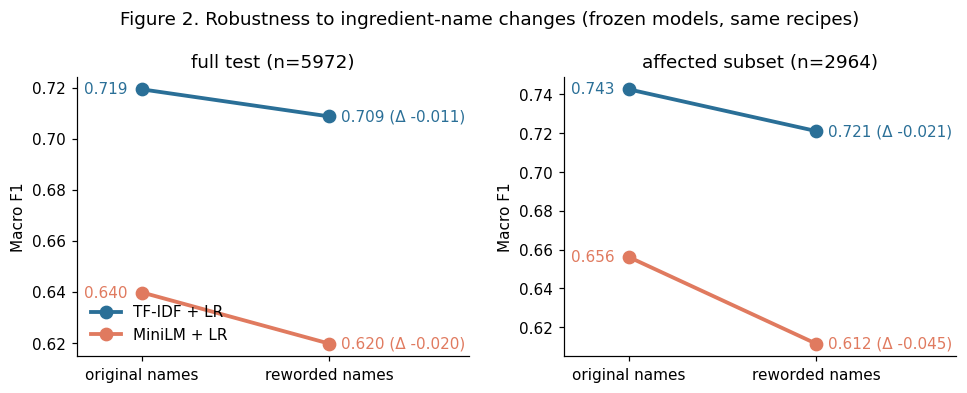

In [29]:
# Figure 2: robustness slope chart (the steeper the line, the less robust the model)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharey=False)
for ax, subset in zip(axes, ["full test", "affected subset"]):
    for m, col in zip(METHODS, [COLOR_TFIDF, COLOR_EMB]):
        r = main_results[(main_results["method"] == m) & (main_results["test set"] == subset)].iloc[0]
        ys = [r["macro F1 original"], r["macro F1 reworded"]]
        ax.plot([0, 1], ys, "-o", color=col, lw=2.5, ms=8, label=m)
        ax.annotate(f"{ys[0]:.3f}", (0, ys[0]), xytext=(-38, 0), textcoords="offset points", va="center", color=col)
        ax.annotate(f"{ys[1]:.3f} (Δ {ys[1]-ys[0]:+.3f})", (1, ys[1]), xytext=(8, 0),
                    textcoords="offset points", va="center", color=col)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["original names", "reworded names"])
    ax.set_xlim(-0.35, 1.75); ax.set_title(f"{subset} (n={int(main_results[main_results['test set']==subset]['n'].iloc[0])})")
    ax.set_ylabel("Macro F1")
axes[0].legend(loc="lower left", frameon=False)
fig.suptitle("Figure 2. Robustness to ingredient-name changes (frozen models, same recipes)")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig2_robustness_slope.png"); plt.show()

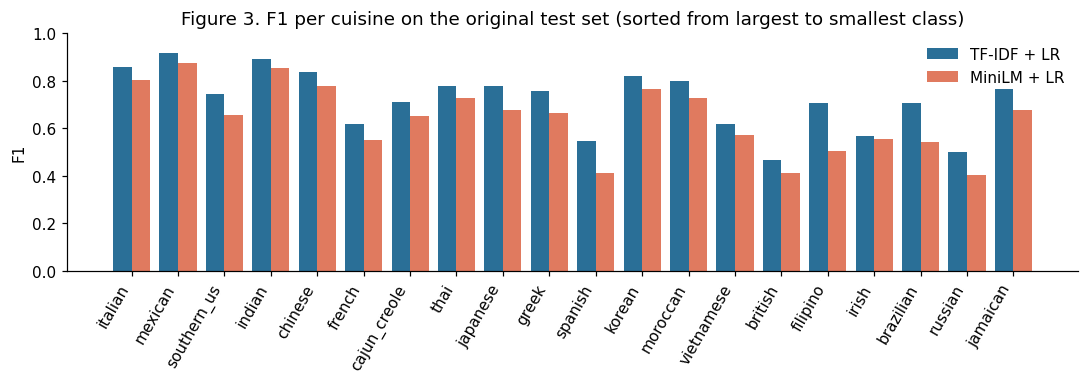

In [30]:
# Per-cuisine F1 on the ORIGINAL test set (which cuisines are hard for each method?)
per_class = pd.DataFrame({
    m: f1_score(y_test, PRED[(m, "original")], average=None, labels=range(K)) for m in METHODS
}, index=CUISINES)
per_class["test recipes"] = pd.Series(y_test).value_counts().reindex(range(K)).fillna(0).astype(int).values
per_class = per_class.sort_values("test recipes", ascending=False)
per_class.round(3).to_csv(RESULTS_DIR / "per_cuisine_f1.csv")

fig, ax = plt.subplots(figsize=(10, 3.6))
x = np.arange(K); w = 0.4
ax.bar(x - w/2, per_class[METHODS[0]], w, color=COLOR_TFIDF, label=METHODS[0])
ax.bar(x + w/2, per_class[METHODS[1]], w, color=COLOR_EMB, label=METHODS[1])
ax.set_xticks(x); ax.set_xticklabels(per_class.index, rotation=60, ha="right")
ax.set_ylabel("F1"); ax.set_ylim(0, 1); ax.legend(frameon=False)
ax.set_title("Figure 3. F1 per cuisine on the original test set (sorted from largest to smallest class)")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig3_per_cuisine_f1.png"); plt.show()

# 8. Error analysis
We look at three things:
1. **Flips** — recipes whose prediction *changes* after the names change. This is the most direct sign of fragility.
2. **Which substitutions** cause the most flips.
3. **Which cuisines get confused**, including naturally close pairs such as Cajun/Creole and Southern US.

Finally, we explain individual mistakes in detail.

In [31]:
def flip_table(mask):
    rows = []
    for m in METHODS:
        po, pr, yt = PRED[(m, "original")][mask], PRED[(m, "reworded")][mask], y_test[mask]
        co, cr = po == yt, pr == yt
        rows.append({
            "method": m,
            "stayed correct": int((co & cr).sum()),
            "stayed wrong (same answer)": int((~co & ~cr & (po == pr)).sum()),
            "correct → wrong": int((co & ~cr).sum()),
            "wrong → correct": int((~co & cr).sum()),
            "wrong → different wrong": int((~co & ~cr & (po != pr)).sum()),
            "flip rate %": round(100 * (po != pr).mean(), 2),
        })
    return pd.DataFrame(rows).set_index("method")

flips = flip_table(affected)
flips.to_csv(RESULTS_DIR / "flip_analysis.csv")
print(f"Table 11. What happens to the {n_aff} affected recipes when ingredient names change")
display(flips)

Table 11. What happens to the 2964 affected recipes when ingredient names change


,stayed correct,stayed wrong (same answer),correct → wrong,wrong → correct,wrong → different wrong,flip rate %
method,,,,,,
TF-IDF + LR,2293,402,104,65,100,9.08
MiniLM + LR,2076,545,145,75,123,11.57


In [32]:
# Which substitutions cause flips? (a recipe with several substitutions is counted for each of them)
flip_mask = {m: PRED[(m, "original")] != PRED[(m, "reworded")] for m in METHODS}
harm_mask = {m: (PRED[(m, "original")] == y_test) & (PRED[(m, "reworded")] != y_test) for m in METHODS}
rows = []
for orig, new, *_ in SUBSTITUTIONS:
    has = test_df["applied"].apply(lambda keys: orig in keys).values
    if has.sum() == 0:
        continue
    row = {"substitution": f"{orig} → {new}", "test recipes": int(has.sum())}
    for m in METHODS:
        short = m.split()[0]
        row[f"{short} flips"] = int(flip_mask[m][has].sum())
        row[f"{short} correct→wrong"] = int(harm_mask[m][has].sum())
    rows.append(row)
sub_flips = pd.DataFrame(rows).sort_values("TF-IDF flips", ascending=False)
sub_flips.to_csv(RESULTS_DIR / "flips_per_substitution.csv", index=False)
print("Table 12. Flips caused by each substitution")
display(sub_flips)

Table 12. Flips caused by each substitution


,substitution,test recipes,TF-IDF flips,TF-IDF correct→wrong,MiniLM flips,MiniLM correct→wrong
11,all purpose flour → plain flour,714,128,33,135,54
20,bell pepper → capsicum,552,51,24,68,29
2,cilantro → coriander leaf,716,49,31,64,30
12,green onions → spring onions,557,37,18,39,11
8,baking soda → bicarbonate of soda,139,22,5,42,19
10,confectioners sugar → icing sugar,67,21,4,22,9
14,scallions → spring onions,292,19,11,14,7
5,zucchini → courgette,130,15,10,21,16
9,powdered sugar → icing sugar,76,11,2,25,12
16,ground beef → beef mince,177,10,7,26,10


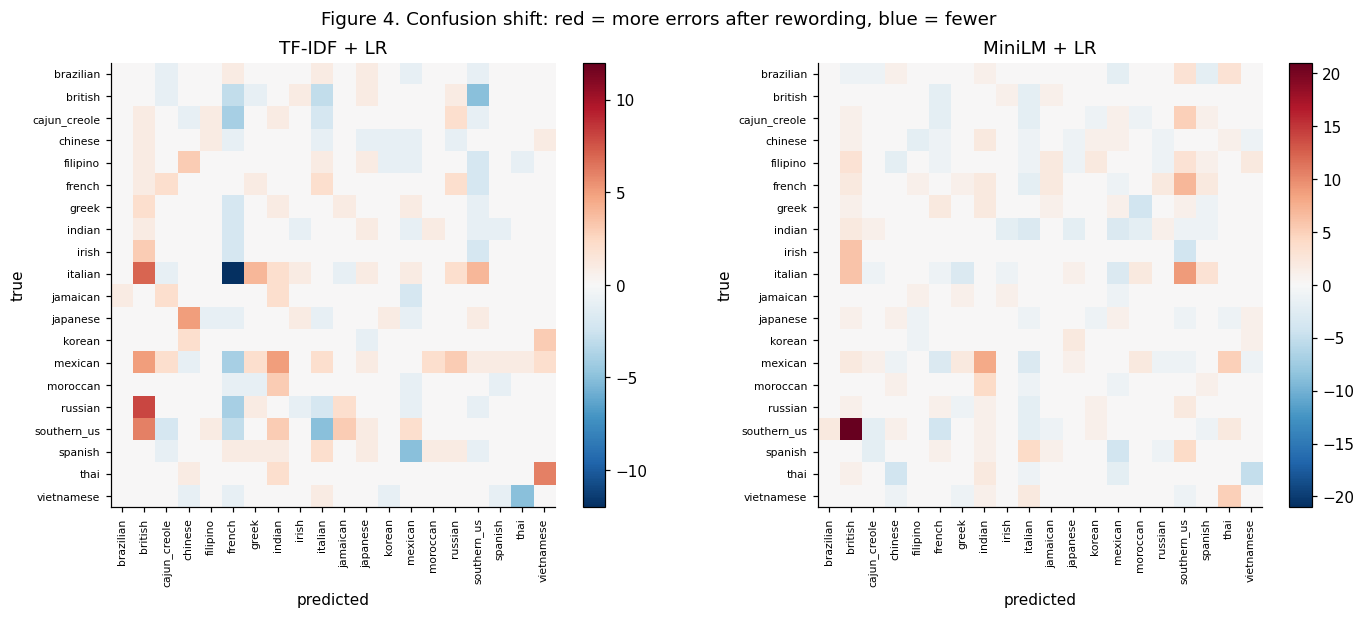

Table 13. New confusions created by rewording (top 10)


,method,true,now predicted as,extra errors
149,MiniLM + LR,southern_us,british,21
122,MiniLM + LR,italian,southern_us,9
136,MiniLM + LR,mexican,indian,8
60,TF-IDF + LR,russian,british,8
30,TF-IDF + LR,italian,british,7
107,MiniLM + LR,french,southern_us,7
63,TF-IDF + LR,southern_us,british,6
78,TF-IDF + LR,thai,vietnamese,6
119,MiniLM + LR,italian,british,6
118,MiniLM + LR,irish,british,6


In [33]:
# Confusion shift: (confusion after rewording) − (confusion before), off-diagonal only
def confusion_shift(m):
    cm_o = confusion_matrix(y_test, PRED[(m, "original")], labels=range(K))
    cm_r = confusion_matrix(y_test, PRED[(m, "reworded")], labels=range(K))
    return cm_r - cm_o

fig, axes = plt.subplots(1, 2, figsize=(13, 5.6))
shift_rows = []
for ax, m in zip(axes, METHODS):
    D = confusion_shift(m)
    np.fill_diagonal(D, 0)
    lim = max(1, np.abs(D).max())
    im = ax.imshow(D, cmap="RdBu_r", vmin=-lim, vmax=lim)
    ax.set_xticks(range(K)); ax.set_xticklabels(CUISINES, rotation=90, fontsize=7)
    ax.set_yticks(range(K)); ax.set_yticklabels(CUISINES, fontsize=7)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(m)
    plt.colorbar(im, ax=ax, fraction=0.046)
    for i, j in zip(*np.where(D > 0)):
        shift_rows.append({"method": m, "true": CUISINES[i], "now predicted as": CUISINES[j], "extra errors": int(D[i, j])})
fig.suptitle("Figure 4. Confusion shift: red = more errors after rewording, blue = fewer")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig4_confusion_shift.png"); plt.show()

shift_table = (pd.DataFrame(shift_rows).sort_values("extra errors", ascending=False)
               if shift_rows else pd.DataFrame(columns=["method", "true", "now predicted as", "extra errors"]))
shift_table.to_csv(RESULTS_DIR / "confusion_shift.csv", index=False)
print("Table 13. New confusions created by rewording (top 10)")
display(shift_table.head(10))

In [34]:
# Close cuisine pairs: how often is one predicted as the other? (original test set)
RELATED_PAIRS = [("cajun_creole", "southern_us"), ("irish", "british"), ("british", "southern_us"),
                 ("chinese", "korean"), ("chinese", "vietnamese"), ("japanese", "korean"),
                 ("thai", "vietnamese"), ("spanish", "mexican"), ("italian", "french"),
                 ("greek", "italian"), ("indian", "moroccan")]
rel_rows = []
for a, b in RELATED_PAIRS:
    if a not in LABEL2ID or b not in LABEL2ID:
        continue
    ia, ib = LABEL2ID[a], LABEL2ID[b]
    row = {"cuisine A": a, "cuisine B": b}
    for m in METHODS:
        p = PRED[(m, "original")]
        a_as_b = ((y_test == ia) & (p == ib)).sum() / max(1, (y_test == ia).sum())
        b_as_a = ((y_test == ib) & (p == ia)).sum() / max(1, (y_test == ib).sum())
        row[f"{m.split()[0]}: A→B %"] = round(100 * a_as_b, 1)
        row[f"{m.split()[0]}: B→A %"] = round(100 * b_as_a, 1)
    rel_rows.append(row)
related = pd.DataFrame(rel_rows)
related.to_csv(RESULTS_DIR / "related_cuisine_confusion.csv", index=False)
print("Table 14. Confusion between culinary neighbours (A→B % = share of true-A test recipes predicted as B)")
display(related)

# Most confused pairs overall (both directions added), per method
for m in METHODS:
    cm = confusion_matrix(y_test, PRED[(m, "original")], labels=range(K)).astype(float)
    np.fill_diagonal(cm, 0)
    sym = cm + cm.T
    iu = np.triu_indices(K, 1)
    top = np.argsort(sym[iu])[::-1][:5]
    pairs = [f"{CUISINES[iu[0][t]]} ↔ {CUISINES[iu[1][t]]} ({int(sym[iu][t])})" for t in top if sym[iu][t] > 0]
    print(f"{m} — most confused pairs: " + ("; ".join(pairs) or "none"))

Table 14. Confusion between culinary neighbours (A→B % = share of true-A test recipes predicted as B)


,cuisine A,cuisine B,TF-IDF: A→B %,TF-IDF: B→A %,MiniLM: A→B %,MiniLM: B→A %
0,cajun_creole,southern_us,17.9,5.5,19.0,6.9
1,irish,british,9.8,2.6,5.4,1.7
2,british,southern_us,18.3,1.1,27.8,0.8
3,chinese,korean,1.6,15.0,2.1,15.7
4,chinese,vietnamese,0.9,11.7,2.3,11.7
5,japanese,korean,1.0,4.3,3.4,4.3
6,thai,vietnamese,6.7,22.7,9.2,21.1
7,spanish,mexican,7.8,0.3,9.8,0.6
8,italian,french,5.1,17.8,5.2,22.3
9,greek,italian,13.0,1.0,21.9,1.7


TF-IDF + LR — most confused pairs: french ↔ italian (129); cajun_creole ↔ southern_us (79); french ↔ southern_us (48); italian ↔ southern_us (46); thai ↔ vietnamese (45)
MiniLM + LR — most confused pairs: french ↔ italian (148); cajun_creole ↔ southern_us (91); french ↔ southern_us (71); italian ↔ southern_us (64); mexican ↔ southern_us (57)


### 8.1 Worked examples — *why* did the prediction change?
For TF‑IDF we can open the “black box”: each word's contribution = (its TF‑IDF value) × (the model's weight for that word and that cuisine). The cell below picks real flipped recipes from the test set and shows the words that pushed the decision most, before and after the rewording.

In [35]:
tf_vec, tf_clf = tfidf_model.named_steps["tfidf"], tfidf_model.named_steps["clf"]
feat_names = np.array(tf_vec.get_feature_names_out())

def top_contributions(text, class_id, k=5):
    x = tf_vec.transform([text])
    contrib = x.multiply(tf_clf.coef_[class_id]).toarray().ravel()
    order = np.argsort(contrib)[::-1][:k]
    return ", ".join(f"{feat_names[i]} ({contrib[i]:+.2f})" for i in order if contrib[i] > 0) or "—"

def show_example(i):
    r = test_df.iloc[i]
    print("=" * 100)
    print(f"Recipe id {r['id']} | TRUE cuisine: {r['cuisine'].upper()} | substitutions: {', '.join(r['applied'])}")
    print("  original :", ", ".join(r["clean"]))
    print("  reworded :", ", ".join(r["clean_reworded"]))
    for m in METHODS:
        po, pr = PRED[(m, "original")][i], PRED[(m, "reworded")][i]
        print(f"  {m:12s}: {CUISINES[po]} ({P[(m,'original')][i, po]:.2f})  →  {CUISINES[pr]} ({P[(m,'reworded')][i, pr]:.2f})"
              + ("   ⚠ changed" if po != pr else ""))
    po, pr = PRED[("TF-IDF + LR", "original")][i], PRED[("TF-IDF + LR", "reworded")][i]
    print(f"  TF-IDF evidence for '{CUISINES[po]}' BEFORE:", top_contributions(X_te_txt.iloc[i], po))
    print(f"  TF-IDF evidence for '{CUISINES[pr]}' AFTER :", top_contributions(X_terw_txt.iloc[i], pr))

# Priority: TF-IDF correct→wrong, then MiniLM correct→wrong, then any flip
order = []
for mask in [harm_mask["TF-IDF + LR"], harm_mask["MiniLM + LR"],
             flip_mask["TF-IDF + LR"] | flip_mask["MiniLM + LR"]]:
    order += [i for i in np.where(mask)[0] if i not in order]
for i in order[:5]:
    show_example(i)
if not order:
    print("No prediction changed — see Section 8.2 for difficult cases instead.")

Recipe id 41710 | TRUE cuisine: FILIPINO | substitutions: green onions
  original : chicken broth, short grain rice, onions, boneless chicken skinless thigh, ginger root, fish sauce, garlic, garlic flakes, green onions, canola oil
  reworded : chicken broth, short grain rice, onions, boneless chicken skinless thigh, ginger root, fish sauce, garlic, garlic flakes, spring onions, canola oil
  TF-IDF + LR : filipino (0.30)  →  chinese (0.26)   ⚠ changed
  MiniLM + LR : chinese (0.29)  →  chinese (0.31)
  TF-IDF evidence for 'filipino' BEFORE: garlic (+0.73), fish_sauce (+0.66), onions (+0.56), thigh (+0.45), chicken (+0.37)
  TF-IDF evidence for 'chinese' AFTER : ginger (+0.82), spring_onions (+0.55), sauce (+0.46), chicken (+0.45), rice (+0.44)
Recipe id 46189 | TRUE cuisine: ITALIAN | substitutions: ground pork
  original : unsalted butter, ground pork, carrots, celery ribs, dry white wine, grated nutmeg, chuck, whole milk, tomatoes with juice, onions, store bought low sodium chicken st

### 8.2 Errors on the original test set (also required by the guidelines)
These are recipes that the better model gets wrong *even without* any rewording. They help explain the general limits of the task (blurry cuisine borders, very short recipes, common ingredients).

In [36]:
best_method = max(METHODS, key=lambda m: macro_f1(y_test, PRED[(m, "original")]))
wrong = np.where(PRED[(best_method, "original")] != y_test)[0]
# Prefer short recipes and confident mistakes: they are the most informative
conf = P[(best_method, "original")].max(1)
wrong = sorted(wrong, key=lambda i: -conf[i])[:3] + sorted(wrong, key=lambda i: len(test_df.iloc[i]["clean"]))[:2]
print(f"Best method on the original test set: {best_method}\n")
if len(wrong) == 0:
    print("No errors on the original test set — explain difficult correct cases instead.")
for i in dict.fromkeys(wrong):
    r = test_df.iloc[i]
    p = PRED[(best_method, "original")][i]
    top3 = np.argsort(P[(best_method, "original")][i])[::-1][:3]
    print(f"TRUE {r['cuisine'].upper():13s} | predicted {CUISINES[p]} ({conf[i]:.2f}) | top-3: "
          + ", ".join(f"{CUISINES[t]} {P[(best_method,'original')][i, t]:.2f}" for t in top3))
    print("   ", ", ".join(r["clean"]), "\n")

Best method on the original test set: TF-IDF + LR

TRUE JAPANESE      | predicted indian (1.00) | top-3: indian 1.00, japanese 0.00, moroccan 0.00
    tomatoes, sugar, whole wheat flour, bay leaves, salt, brown cardamom, oil, onions, ground cumin, tea bags, water, coriander seeds, seeds, all purpose flour, curds, cinnamon sticks, boiling potatoes, clove, asafoetida, amchur, baking soda, chili powder, chickpeas, cumin seed, nigella seeds, ginger paste, black peppercorns, red chili peppers, mace, baking powder, cilantro leaves, green chilies, lemon juice, chaat masala 

TRUE FRENCH        | predicted italian (0.99) | top-3: italian 0.99, french 0.00, mexican 0.00
    garlic cloves, grated parmesan cheese, salt, olive oil, fresh basil leaves 

TRUE FRENCH        | predicted italian (0.99) | top-3: italian 0.99, french 0.00, spanish 0.00
    pepper, veal cutlets, asparagus spears, olive oil, fresh mushrooms, italian cheese, prosciutto, garlic cloves, water, salt 

TRUE VIETNAMESE    | pred

### 8.3 Our explanation of the errors

#### A. Recipes whose prediction changed after the name swaps

**1. Recipe 41710 (true: Filipino) — *green onions → spring onions***
TF-IDF changed from Filipino (0.30) to Chinese (0.26). After the swap, the strongest Chinese clues were *ginger* and *spring_onions*, so in the training data "spring onions" is a Chinese clue. The two scores were already very close, because Filipino and Chinese food share many ingredients (ginger, rice, chicken). One small change was enough to tip the decision.

**2. Recipe 46189 (true: Italian) — *ground pork → pork mince***
This is a Bolognese-style sauce (wine, milk, nutmeg, carrots, celery), so a human would say Italian. TF-IDF changed to Southern US. Without the phrase "ground pork", the words *pork*, *butter* and *celery* pushed it to Southern US. MiniLM was wrong both times.

**3. Recipe 8082 (true: Southern US) — *all purpose flour → plain flour, baking soda → bicarbonate of soda***
This is the clearest "dialect" error. **Both** models changed to **British**. The TF-IDF evidence shows *plain_flour* (+0.44) and *bicarbonate_of_soda* (+0.40) as British clues. The food did not change, only the English, but the models followed the English.

**4. Recipe 21110 (true: Greek) — *baking soda, all purpose flour***
TF-IDF changed from Greek (0.26) to Jamaican (0.30). The only strong Greek clue was the word *greek* in "greek yogurt"; the rest (pumpkin, pecans, bananas, brown sugar) is not typical Greek food. The model was unsure before the swap, and *plain_flour* was enough to change the answer. This is a hard case even for a human.

**5. Recipe 24081 (true: Mexican) — *cilantro → coriander leaf***
A short recipe with only 5 ingredients. *Cilantro* was the strongest Mexican clue (+1.10). After the swap, TF-IDF chose Russian (because of *cabbage*), and MiniLM chose Thai, because "coriander" is common in Thai cooking. Short recipes are fragile, because losing one clue can change everything.

#### B. Errors on the original test set (no swaps)

- **Japanese → Indian (1.00):** the recipe contains cardamom, asafoetida, amchur and nigella seeds, which are typical Indian spices. The label is probably wrong in the dataset.
- **French → Italian (0.99), twice:** garlic, parmesan, olive oil and basil (or prosciutto and "italian cheese") look Italian to any human. Cuisine borders are blurry.
- **Vietnamese → Chinese** (*dried rice noodles* only) and **Korean → Russian** (*water, barley* only): one or two ingredients are not enough information to decide.

#### C. Main patterns
1. **The models learn the dialect, not only the food.** British words such as *plain flour* and *bicarbonate of soda* push recipes towards British cuisine.
2. **Short recipes and close scores are fragile:** one changed word can flip the answer.
3. **Some errors come from the data itself:** wrong labels and cuisines that share many ingredients.

# 9. Our own labelled examples
Each team member wrote **two original recipes** with the cuisine we expect. These are **not** part of the test set and are **not** used in any score above; they only show how the system behaves on brand-new text.



In [44]:
TEAM_EXAMPLES = [
    # (member name, ingredients separated by commas, expected cuisine)

    # Member 1
    ("Maisoon", "spaghetti, tomato sauce, garlic, basil, parmesan cheese, olive oil", "italian"),      # easy recipe
    ("Maisoon", "aubergine, courgette, tomatoes, garlic, olive oil, fresh thyme", "french"),           # tricky: British names (ratatouille)

    # Member 2
    ("Wajd", "soy sauce, ginger, garlic, sesame oil, tofu, green onions, rice", "chinese"),            # easy recipe
    ("Wajd", "basmati rice, chicken, onion, tomato, cardamom, cinnamon, dried lime, black pepper", "indian"),  # tricky: Saudi Kabsa (no Saudi label)

    # Member 3
    ("Jolie", "corn tortillas, black beans, avocado, lime, cilantro, jalapeno chilies", "mexican"),    # easy recipe
    ("Jolie", "corn tortillas, black beans, avocado, lime, coriander leaf, jalapeno chilies", "mexican"),  # tricky: same recipe, cilantro -> coriander leaf

    # Member 4
    ("Manar", "fish sauce, coconut milk, lemongrass, red curry paste, chicken, thai basil", "thai"),   # easy recipe
    ("Manar", "plain flour, butter, buttermilk, bicarbonate of soda, sausages, cheddar cheese", "southern_us"),  # tricky: US biscuits in British words
]

# 10. Try it ✨
Type any comma-separated ingredients in the box on the right (in Colab), then run the cell.
- The models are **loaded from the saved files** in `models/`, so nothing is retrained.
- You get the **top 3 cuisines** from each method, the **ingredients that drove** the TF‑IDF decision, and a warning for any word the TF‑IDF model has **never seen**.
- Empty input gives a friendly message.

In [38]:
# Load the frozen models from disk (works in a fresh session after Sections 0-6 have been run once)
_tfidf = joblib.load(MODELS_DIR / "tfidf_lr.joblib")
_emb_pack = joblib.load(MODELS_DIR / "minilm_lr.joblib")
_emb_clf = _emb_pack["classifier"]

def predict_cuisine(ingredients_text, method="both", top_k=3, verbose=True):
    """Predict the cuisine of a comma-separated ingredient list without retraining."""
    if ingredients_text is None or not str(ingredients_text).strip():
        print("🥄 Please type at least one ingredient, e.g. 'tomato, garlic, basil'.")
        return None
    phrases = clean_recipe(str(ingredients_text).split(","))
    if not phrases:
        print("🥄 I could not find any ingredient words. Please use letters, separated by commas.")
        return None
    results = {}
    if method in ("both", "tfidf"):
        text = to_tfidf_text(phrases)
        proba = _tfidf.predict_proba([text])[0]
        results["TF-IDF + LR"] = proba
        unknown = [t for t in _tfidf.named_steps["tfidf"].build_analyzer()(" ".join(phrases))
                   if t not in _tfidf.named_steps["tfidf"].vocabulary_]
    if method in ("both", "minilm"):
        e = encoder.encode([to_sentence(phrases)], normalize_embeddings=True)
        results["MiniLM + LR"] = _emb_clf.predict_proba(e)[0]
    if verbose:
        print("Ingredients understood:", ", ".join(phrases))
        for m, proba in results.items():
            top = np.argsort(proba)[::-1][:top_k]
            print(f"\n{m}")
            for t in top:
                print(f"   {CUISINES[t]:14s} {'█' * int(round(proba[t] * 30)):30s} {proba[t]:.2f}")
        if "TF-IDF + LR" in results:
            best_t = int(np.argmax(results["TF-IDF + LR"]))
            x = _tfidf.named_steps["tfidf"].transform([to_tfidf_text(phrases)])
            contrib = x.multiply(_tfidf.named_steps["clf"].coef_[best_t]).toarray().ravel()
            names = _tfidf.named_steps["tfidf"].get_feature_names_out()
            top_w = [names[i] for i in np.argsort(contrib)[::-1][:5] if contrib[i] > 0]
            print(f"\nWhy TF-IDF chose '{CUISINES[best_t]}':", ", ".join(top_w) if top_w else "—")
            if unknown:
                print("⚠ Words the TF-IDF model has never seen (ignored by it):", ", ".join(sorted(set(unknown))))
    return {m: CUISINES[int(np.argmax(p))] for m, p in results.items()}

print("✔ Models loaded. Use the form below.")

✔ Models loaded. Use the form below.


In [39]:
#@title 🍳 Try it: type your ingredients
ingredients = "aubergine, tomato, garlic, olive oil, basil, parmesan cheese"  #@param {type:"string"}
method = "both"  #@param ["both", "tfidf", "minilm"]
predict_cuisine(ingredients, method)

Ingredients understood: aubergine, tomato, garlic, olive oil, basil, parmesan cheese

TF-IDF + LR
   italian        ██████████████████████████████ 1.00
   greek                                         0.00
   french                                        0.00

MiniLM + LR
   italian        ██████████████████████████████ 1.00
   french                                        0.00
   southern_us                                   0.00

Why TF-IDF chose 'italian': parmesan, basil, cheese, olive, olive_oil
⚠ Words the TF-IDF model has never seen (ignored by it): aubergine


{'TF-IDF + LR': 'italian', 'MiniLM + LR': 'italian'}

In [40]:
# Live-demo idea: the same recipe written in two "dialects"
for version in ["eggplant, tomatoes, garlic, olive oil, basil, mozzarella cheese",
                "aubergine, tomatoes, garlic, olive oil, basil, mozzarella cheese"]:
    print("─" * 70); print("INPUT:", version)
    predict_cuisine(version)
print("─" * 70)
predict_cuisine("")   # empty-input handling

──────────────────────────────────────────────────────────────────────
INPUT: eggplant, tomatoes, garlic, olive oil, basil, mozzarella cheese
Ingredients understood: eggplant, tomatoes, garlic, olive oil, basil, mozzarella cheese

TF-IDF + LR
   italian        ██████████████████████████████ 0.99
   greek                                         0.00
   french                                        0.00

MiniLM + LR
   italian        █████████████████████████████  0.96
   spanish        █                              0.02
   greek                                         0.01

Why TF-IDF chose 'italian': mozzarella, basil, cheese, olive, olive_oil
──────────────────────────────────────────────────────────────────────
INPUT: aubergine, tomatoes, garlic, olive oil, basil, mozzarella cheese
Ingredients understood: aubergine, tomatoes, garlic, olive oil, basil, mozzarella cheese

TF-IDF + LR
   italian        ██████████████████████████████ 1.00
   mexican                                      

In [45]:
# Our own labelled examples (Section 9), shown separately from the test scores
team_rows = []
for member, text, expected in TEAM_EXAMPLES:
    preds = predict_cuisine(text, verbose=False)
    team_rows.append({"member": member, "ingredients": text, "expected": expected,
                      "TF-IDF + LR": preds["TF-IDF + LR"], "MiniLM + LR": preds["MiniLM + LR"]})
team_table = pd.DataFrame(team_rows)
team_table.to_csv(RESULTS_DIR / "team_examples.csv", index=False)
print("Table 15. Team members' original examples (not part of the test scores)")
display(team_table)

Table 15. Team members' original examples (not part of the test scores)


,member,ingredients,expected,TF-IDF + LR,MiniLM + LR
0,Maisoon,"spaghetti, tomato sauce, garlic, basil, parmesan cheese, olive oil",italian,italian,italian
1,Maisoon,"aubergine, courgette, tomatoes, garlic, olive oil, fresh thyme",french,french,italian
2,Wajd,"soy sauce, ginger, garlic, sesame oil, tofu, green onions, rice",chinese,chinese,chinese
3,Wajd,"basmati rice, chicken, onion, tomato, cardamom, cinnamon, dried lime, black pepper",indian,indian,indian
4,Jolie,"corn tortillas, black beans, avocado, lime, cilantro, jalapeno chilies",mexican,mexican,mexican
5,Jolie,"corn tortillas, black beans, avocado, lime, coriander leaf, jalapeno chilies",mexican,mexican,mexican
6,Manar,"fish sauce, coconut milk, lemongrass, red curry paste, chicken, thai basil",thai,thai,thai
7,Manar,"plain flour, butter, buttermilk, bicarbonate of soda, sausages, cheddar cheese",southern_us,british,british


# 11. Saved results summary


In [42]:
def get(m, subset, col):
    return float(main_results[(main_results["method"] == m) & (main_results["test set"] == subset)][col].iloc[0])

summary = {
    "dataset": {"recipes_used": len(df), "cuisines": K, "train": len(train_df), "dev": len(dev_df), "test": len(test_df)},
    "coverage": coverage,
    "selected_settings": {"TF-IDF + LR": tfidf_dev.loc[tfidf_dev["dev macro F1"].idxmax(), ["C", "class_weight"]].to_dict(),
                          "MiniLM + LR": emb_dev.loc[emb_dev["dev macro F1"].idxmax(), ["C", "class_weight"]].to_dict()},
    "results": {m: {s: {k: round(get(m, s, k), 4) for k in ["acc original", "acc reworded", "macro F1 original",
                                                            "macro F1 reworded", "Δ macro F1"]}
                    for s in ["full test", "affected subset"]} for m in METHODS},
    "flip_rate_affected_%": flips["flip rate %"].to_dict(),
}
(RESULTS_DIR / "summary.json").write_text(json.dumps(summary, indent=2, default=str))
print(json.dumps(summary, indent=2, default=str))

d_tf = get("TF-IDF + LR", "affected subset", "Δ macro F1")
d_em = get("MiniLM + LR", "affected subset", "Δ macro F1")
more_robust = "MiniLM + LR" if d_em > d_tf else "TF-IDF + LR"
print(f"\nAnswer to the experimental question (affected subset): ΔF1 TF-IDF = {d_tf:+.4f}, "
      f"ΔF1 MiniLM = {d_em:+.4f} → the smaller drop belongs to {more_robust}. "
      "Check Table 10 to see whether this difference is larger than chance.")

{
  "dataset": {
    "recipes_used": 39774,
    "cuisines": 20,
    "train": 27838,
    "dev": 5964,
    "test": 5972
  },
  "coverage": {
    "test recipes": 5972,
    "affected recipes": 2964,
    "affected %": 49.6,
    "total substitutions": 4162,
    "mean substitutions per affected recipe": 1.4
  },
  "selected_settings": {
    "TF-IDF + LR": {
      "C": 3,
      "class_weight": "none"
    },
    "MiniLM + LR": {
      "C": 50,
      "class_weight": "none"
    }
  },
  "results": {
    "TF-IDF + LR": {
      "full test": {
        "acc original": 0.7922,
        "acc reworded": 0.7857,
        "macro F1 original": 0.7193,
        "macro F1 reworded": 0.7087,
        "\u0394 macro F1": -0.0106
      },
      "affected subset": {
        "acc original": 0.8087,
        "acc reworded": 0.7955,
        "macro F1 original": 0.7425,
        "macro F1 reworded": 0.7211,
        "\u0394 macro F1": -0.0215
      }
    },
    "MiniLM + LR": {
      "full test": {
        "acc original": 0

# 12. Sources
**Data**
- Yummly / Kaggle (2015). *What's Cooking?* competition data. https://www.kaggle.com/c/whats-cooking — public copy used for download: *Recipe Ingredients Dataset*, https://www.kaggle.com/datasets/kaggle/recipe-ingredients-dataset

**Related work**
- Y.-Y. Ahn, S. E. Ahnert, J. P. Bagrow and A.-L. Barabási, “Flavor network and the principles of food pairing,” *Scientific Reports*, vol. 1, 196, 2011.
- N. Reimers and I. Gurevych, “Sentence-BERT: Sentence embeddings using Siamese BERT-networks,” in *Proc. EMNLP-IJCNLP*, 2019.
- W. Wang, F. Wei, L. Dong, H. Bao, N. Yang and M. Zhou, “MiniLM: Deep self-attention distillation for task-agnostic compression of pre-trained transformers,” in *Proc. NeurIPS*, 2020.
- M. T. Ribeiro, T. Wu, C. Guestrin and S. Singh, “Beyond accuracy: Behavioral testing of NLP models with CheckList,” in *Proc. ACL*, 2020. *(Idea of testing models with meaning-preserving changes to the input.)*

**Methods and tools**
- F. Pedregosa et al., “Scikit-learn: Machine learning in Python,” *JMLR*, vol. 12, pp. 2825–2830, 2011.
- B. Efron and R. J. Tibshirani, *An Introduction to the Bootstrap*. Chapman & Hall, 1993.
- Pretrained weights: `sentence-transformers/all-MiniLM-L6-v2` (Hugging Face, Apache-2.0).


In [43]:
!zip -r results_and_figures.zip results figures
from google.colab import files
files.download("results_and_figures.zip")

  adding: results/ (stored 0%)
  adding: results/bootstrap_ci.csv (deflated 48%)
  adding: results/per_cuisine_f1.csv (deflated 38%)
  adding: results/main_results.csv (deflated 46%)
  adding: results/class_counts.csv (deflated 35%)
  adding: results/vocabulary_check.csv (deflated 71%)
  adding: results/dev_tuning_tfidf.csv (deflated 33%)
  adding: results/flips_per_substitution.csv (deflated 51%)
  adding: results/dev_tuning_minilm.csv (deflated 34%)
  adding: results/flip_analysis.csv (deflated 25%)
  adding: results/split_sizes.csv (deflated 9%)
  adding: results/confusion_shift.csv (deflated 84%)
  adding: results/team_examples.csv (deflated 47%)
  adding: results/substitutions_applied.csv (deflated 65%)
  adding: results/coverage_per_pair.csv (deflated 50%)
  adding: results/related_cuisine_confusion.csv (deflated 39%)
  adding: results/substitutions_excluded.csv (deflated 54%)
  adding: results/summary.json (deflated 71%)
  adding: results/coverage_per_cuisine.csv (deflated 35%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>